# Santander Value Prediction — Feature Engineering

Test whether row-level aggregate features improve the selected 300-tree LightGBM on this zero-heavy, high-dimensional dataset. Use the original 80/20 split and the same five training-only CV folds.

**Reference mean CV RMSLE:** **1.4668**. The holdout was inspected earlier and is used only for an exploratory performance check.

In [1]:
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor
from sklearn.datasets import fetch_openml
from sklearn.model_selection import KFold, cross_validate, train_test_split

RANDOM_STATE = 42

In [22]:
dataset = fetch_openml(
    data_id=42572,
    as_frame=True,
)

X = dataset.data.copy()
y = pd.to_numeric(dataset.target)

# Exclude an identifier if present
X = X.drop(columns=["ID"], errors="ignore")

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.iloc[:5, :5])

Features shape: (4459, 4991)
Target shape: (4459,)


,48df886f9,0deb4b6a8,34b15f335,a8cb14b00,2f0771a37
0,0.0,0,0.0,0,0
1,0.0,0,0.0,0,0
2,0.0,0,0.0,0,0
3,0.0,0,0.0,0,0
4,0.0,0,0.0,0,0


In [3]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (3567, 4991)
X_val: (892, 4991)
y_train: (3567,)
y_val: (892,)


In [4]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

y_train_log = np.log1p(y_train)

print("CV folds:", cv.get_n_splits())
print("Log-transformed target:", y_train_log.shape)

CV folds: 5
Log-transformed target: (3567,)


## Reference LightGBM setup

Keep model hyperparameters fixed to isolate the effect of newly engineered features.

In [5]:
lgbm_params = {
    "n_estimators": 300,
    "learning_rate": 0.05,
    "num_leaves": 15,
    "max_depth": 6,
    "min_child_samples": 80,
    "colsample_bytree": 0.7,
    "reg_lambda": 1.0,
    "random_state": RANDOM_STATE,
    "verbosity": -1,
    "n_jobs": 4,
}

## 1. Non-zero feature count

Test whether the number of non-zero original features in each observation adds predictive information.

In [6]:
X_train_fe = X_train.copy()

X_train_fe["nonzero_count"] = (
    X_train.ne(0).sum(axis=1)
)

print("Original shape:", X_train.shape)
print("Engineered shape:", X_train_fe.shape)

display(X_train_fe["nonzero_count"].describe())

Original shape: (3567, 4991)
Engineered shape: (3567, 4992)


count    3567.000000
mean      158.193160
std       214.079753
min         1.000000
25%        34.000000
50%       103.000000
75%       198.000000
max      1989.000000
Name: nonzero_count, dtype: float64

In [7]:
results = []

for name, features in {
    "Baseline": X_train,
    "With nonzero_count": X_train_fe,
}.items():

    model = LGBMRegressor(**lgbm_params)

    scores = cross_validate(
        model,
        features,
        y_train_log,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=1,
    )

    rmsle = -scores["test_score"]

    results.append({
        "model": name,
        "cv_rmsle": rmsle.mean(),
        "std_cv": rmsle.std(),
        "fit_time": scores["fit_time"].mean(),
    })

comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))

,model,cv_rmsle,std_cv,fit_time
0,Baseline,1.4668,0.0232,1.1292
1,With nonzero_count,1.4672,0.0292,0.9147


**Result:** Adding `nonzero_count` changes mean CV RMSLE from **1.4668** to **1.4672**. Do not retain it.

## 2. Row sum

Sum original feature values within each observation; inspect extreme magnitudes before modeling.

In [8]:
X_train_sum = X_train.copy()

X_train_sum["row_sum"] = X_train.sum(axis=1)

display(
    X_train_sum["row_sum"].describe(
        percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]
    )
)

count    3.567000e+03
mean     1.408756e+09
std      2.414495e+09
min      4.000000e+03
1%       1.506040e+06
25%      1.294381e+08
50%      5.413030e+08
75%      1.524405e+09
99%      1.246490e+10
max      2.251345e+10
Name: row_sum, dtype: float64

**Distribution:** `row_sum` is strongly right-skewed (median ~541.3M; maximum ~22.5B). Keep original values for the first LightGBM comparison.

In [9]:
row_sum_results = []

for name, features in {
    "Baseline": X_train,
    "With row_sum": X_train_sum,
}.items():

    model = LGBMRegressor(**lgbm_params)

    scores = cross_validate(
        model,
        features,
        y_train_log,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=1,
    )

    rmsle = -scores["test_score"]

    row_sum_results.append({
        "model": name,
        "cv_rmsle": rmsle.mean(),
        "std_cv": rmsle.std(),
        "fit_time": scores["fit_time"].mean(),
    })

row_sum_df = pd.DataFrame(row_sum_results)

display(row_sum_df.round(4))

,model,cv_rmsle,std_cv,fit_time
0,Baseline,1.4668,0.0232,0.9625
1,With row_sum,1.4402,0.0160,0.9793


**Result:** Adding `row_sum` improves mean CV RMSLE from **1.4668** to **1.4402**. Retain it.

## 3. Row maximum

Test whether the largest original value in each row adds information beyond `row_sum`.

In [10]:
X_train_sum_max = X_train_sum.copy()

X_train_sum_max["row_max"] = X_train.max(axis=1)

results = []

for name, features in {
    "row_sum": X_train_sum,
    "row_sum + row_max": X_train_sum_max,
}.items():

    model = LGBMRegressor(**lgbm_params)

    scores = cross_validate(
        model,
        features,
        y_train_log,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=1,
    )

    rmsle = -scores["test_score"]

    results.append({
        "features": name,
        "cv_rmsle": rmsle.mean(),
        "std_cv": rmsle.std(),
    })

max_comparison_df = pd.DataFrame(results)

display(max_comparison_df.round(4))

,features,cv_rmsle,std_cv
0,row_sum,1.4402,0.0160
1,row_sum + row_max,1.4329,0.0156


**Result:** Adding `row_max` alongside `row_sum` improves mean CV RMSLE from **1.4402** to **1.4329**. Retain it.

## 4. Maximum-value share

Test `row_max_share = row_max / row_sum` as a measure of concentration. Both aggregates are computed from original columns.

In [11]:
X_train_share = X_train_sum_max.copy()

X_train_share["row_max_share"] = (
    X_train_share["row_max"] / X_train_share["row_sum"]
)

results = []

for name, features in {
    "sum + max": X_train_sum_max,
    "sum + max + share": X_train_share,
}.items():

    model = LGBMRegressor(**lgbm_params)

    scores = cross_validate(
        model,
        features,
        y_train_log,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=1,
    )

    rmsle = -scores["test_score"]

    results.append({
        "features": name,
        "cv_rmsle": rmsle.mean(),
        "std_cv": rmsle.std(),
    })

share_df = pd.DataFrame(results)
display(share_df.round(4))

,features,cv_rmsle,std_cv
0,sum + max,1.4329,0.0156
1,sum + max + share,1.4304,0.0181


**Result:** Adding `row_max_share` improves mean CV RMSLE from **1.4329** to **1.4304**. Retain it provisionally; the incremental gain is small.

In [12]:
def add_engineered_features(X: pd.DataFrame) -> pd.DataFrame:
    X_new = X.copy()

    row_sum = X.sum(axis=1)
    row_max = X.max(axis=1)

    X_new["row_sum"] = row_sum
    X_new["row_max"] = row_max

    X_new["row_max_share"] = (
        row_max / row_sum.replace(0, np.nan)
    ).fillna(0)

    return X_new


X_train_final = add_engineered_features(X_train)

print("Original:", X_train.shape)
print("Engineered:", X_train_final.shape)

pd.testing.assert_frame_equal(
    X_train_share,
    X_train_final,
)

print("Feature engineering verified!")

Original: (3567, 4991)
Engineered: (3567, 4994)
Feature engineering verified!


## Holdout comparison

Fit on the training partition and compare original versus engineered features on the previously inspected holdout. This is **not an unbiased final test**.

In [13]:
from sklearn.metrics import mean_squared_log_error

X_val_final = add_engineered_features(X_val)

holdout_results = []

for name, train_features, val_features in [
    ("Original", X_train, X_val),
    ("Engineered", X_train_final, X_val_final),
]:
    model = LGBMRegressor(**lgbm_params)

    model.fit(train_features, y_train_log)

    predictions_log = model.predict(val_features)

    predictions = np.clip(
        np.expm1(predictions_log), 0, None
    )

    rmsle = np.sqrt(
        mean_squared_log_error(y_val, predictions)
    )

    holdout_results.append({
        "features": name,
        "holdout_rmsle": rmsle,
    })

holdout_df = pd.DataFrame(holdout_results)

display(holdout_df.round(4))

,features,holdout_rmsle
0,Original,1.4504
1,Engineered,1.4147


**Result:** Holdout RMSLE decreases from **1.4504** (original) to **1.4147** (engineered), consistent with the CV direction. The holdout was used earlier in development; avoid claiming this is a pristine final test.

## Feature importance

Inspect LightGBM split **gain** for the engineered features; this is model-specific, not a causal explanation.

In [14]:
importance_model = LGBMRegressor(
    **lgbm_params,
    importance_type="gain",
)

importance_model.fit(X_train_final, y_train_log)

importance_df = pd.DataFrame({
    "feature": X_train_final.columns,
    "gain": importance_model.feature_importances_,
})

importance_df = (
    importance_df
    .sort_values("gain", ascending=False)
    .reset_index(drop=True)
)

importance_df["rank"] = importance_df.index + 1

# Top 10 features
display(importance_df.head(10))

# Engineered feature rankings
engineered_features = [
    "row_sum",
    "row_max",
    "row_max_share",
]

display(
    importance_df[
        importance_df["feature"].isin(engineered_features)
    ]
)

,feature,gain,rank
0,row_max,11462.909355,1
1,f190486d6,5476.220011,2
2,row_sum,3300.416044,3
3,eeb9cd3aa,2377.652555,4
4,row_max_share,2139.218778,5
5,58e056e12,1456.628167,6
6,58e2e02e6,1372.955501,7
7,15ace8c9f,1300.650442,8
8,20aa07010,1151.847134,9
9,186b87c05,974.409988,10


,feature,gain,rank
0,row_max,11462.909355,1
2,row_sum,3300.416044,3
4,row_max_share,2139.218778,5


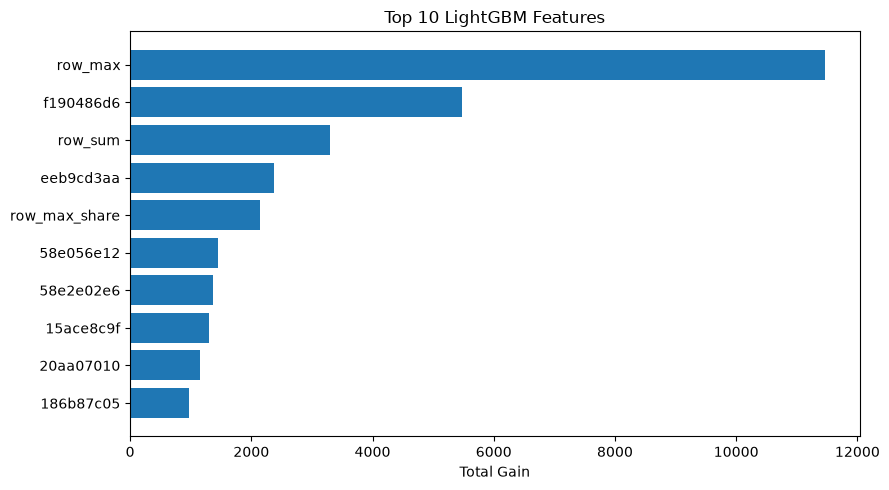

In [15]:
import matplotlib.pyplot as plt

top_features = (
    importance_df.head(10)
    .sort_values("gain")
)

plt.figure(figsize=(9, 5))

plt.barh(
    top_features["feature"],
    top_features["gain"]
)

plt.xlabel("Total Gain")
plt.title("Top 10 LightGBM Features")

plt.tight_layout()
plt.show()

## Feature engineering summary

| Features | Mean 5-fold CV RMSLE |
|---|---:|
| Original 4,991 features | 1.4668 |
| + `row_sum` | 1.4402 |
| + `row_max` | 1.4329 |
| **+ `row_max_share`** | **1.4304** |

`row_max`, `row_sum`, and `row_max_share` rank **1st, 3rd, and 5th** by training gain, respectively. This supports further evaluation but does not establish individual causal contributions.

**Decision:** Keep the three row-level features and consolidate their computation for inference.

## Model artifact

Fit LightGBM on the training partition and save the estimator, expected feature columns, and target-transform metadata in `models/`.

In [16]:
from pathlib import Path

import joblib

# Locate the project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Create the models directory
model_dir = project_root / "models"
model_dir.mkdir(exist_ok=True)

# Train the selected model
final_model = LGBMRegressor(**lgbm_params)

final_model.fit(X_train_final, y_train_log)

# Save the model and its feature schema
model_path = model_dir / "santander_lgbm.joblib"

joblib.dump(
    {
        "model": final_model,
        "feature_columns": X_train_final.columns.tolist(),
        "target_transform": "log1p",
    },
    model_path,
)

print("Model saved to:", model_path)

Model saved to: /Users/ebrietas/santander-value-prediction/models/santander_lgbm.joblib


In [17]:
saved_artifact = joblib.load(model_path)

loaded_model = saved_artifact["model"]

print("Model loaded successfully!")
print("Expected features:", len(saved_artifact["feature_columns"]))
print("Model type:", type(loaded_model).__name__)

Model loaded successfully!
Expected features: 4994
Model type: LGBMRegressor


In [18]:
import sys
from pathlib import Path

# Find project root
project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Make src importable
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.features import add_engineered_features as module_features

# Verify identical outputs
X_test = module_features(X_train)

pd.testing.assert_frame_equal(
    X_train_final,
    X_test,
)

print("Module verified successfully!")

Module verified successfully!


In [19]:
from src.predict import predict_values

sample = X_train.head(5)

predictions = predict_values(sample)

print("Predictions:", predictions)
print("Number of predictions:", len(predictions))

Predictions: [ 2200540.49724106 24242441.11387117  1631881.85300951   206236.89166457
  1499836.01427173]
Number of predictions: 5


## Reusable inference check

Verify that `src/features.py` and `src/predict.py` reproduce direct predictions from the saved model.

In [20]:
import joblib
import numpy as np

from src.features import add_engineered_features
from src.predict import predict_values

# Load the saved model
artifact = joblib.load(
    project_root / "models" / "santander_lgbm.joblib"
)

# Select five raw observations
sample = X_train.head(5)

# Method 1: Predict through our reusable module
module_predictions = predict_values(sample)

# Method 2: Predict directly using the saved model
sample_fe = add_engineered_features(sample)
sample_fe = sample_fe[artifact["feature_columns"]]

direct_predictions = np.clip(
    np.expm1(artifact["model"].predict(sample_fe)),
    0,
    None,
)

# Compare predictions
np.testing.assert_allclose(
    module_predictions,
    direct_predictions,
    rtol=1e-10,
)

print("Prediction consistency verified!")

Prediction consistency verified!


In [21]:
invalid_sample = X_train.head(2).drop(
    columns=X_train.columns[0]
)

try:
    predict_values(invalid_sample)

except ValueError as error:
    print("Invalid input rejected:", error)

else:
    raise AssertionError(
        "Missing feature was not detected!"
    )

Invalid input rejected: Input feature schema does not match the model.


**Validation:** Missing input columns correctly trigger `ValueError`, preventing predictions with an incompatible feature schema.